In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [ ]:
df = pd.read_csv("delhi_bus_passengers_2025_weather_crowd_based_synthetic.csv")

df.head()

,Date,Time,Route_ID,Location,Day_of_Week,Is_Weekend,temp_c,humidity,windspeed_kph,aqi_index,...,Nearby_Crowd_Count,Crowd_Place,Crowd_Date,Crowd_Time,Holiday,Event,Passenger_Count,Bus_Capacity,Occupancy_Percent,Data_Type
0,2025-01-01,06:00:00,SYN001,Anand Vihar,Wednesday,0,8.1,99,4.8,201,...,46113.0,"India Gate, Delhi",2025-01-03,09:50:00,No,National Holiday,44,50,88.0,SYNTHETIC — target generated from actual 2025 ...
1,2025-01-01,07:00:00,SYN001,Anand Vihar,Wednesday,0,8.0,99,4.0,201,...,46113.0,"India Gate, Delhi",2025-01-03,09:50:00,No,National Holiday,61,45,135.6,SYNTHETIC — target generated from actual 2025 ...
2,2025-01-01,08:00:00,SYN001,Anand Vihar,Wednesday,0,8.4,99,6.5,200,...,46113.0,"India Gate, Delhi",2025-01-03,09:50:00,No,National Holiday,84,45,186.7,SYNTHETIC — target generated from actual 2025 ...
3,2025-01-01,09:00:00,SYN001,Anand Vihar,Wednesday,0,9.4,97,8.0,200,...,46113.0,"India Gate, Delhi",2025-01-03,09:50:00,No,National Holiday,74,45,164.4,SYNTHETIC — target generated from actual 2025 ...
4,2025-01-01,12:00:00,SYN001,Anand Vihar,Wednesday,0,14.6,77,6.3,200,...,46113.0,"India Gate, Delhi",2025-01-03,09:50:00,No,National Holiday,51,50,102.0,SYNTHETIC — target generated from actual 2025 ...


In [ ]:
print(df.shape)
print(df.columns.tolist())
df.info()

(21900, 23)
['Date', 'Time', 'Route_ID', 'Location', 'Day_of_Week', 'Is_Weekend', 'temp_c', 'humidity', 'windspeed_kph', 'aqi_index', 'pm2_5', 'pm10', 'condition_text', 'Nearby_Crowd_Count', 'Crowd_Place', 'Crowd_Date', 'Crowd_Time', 'Holiday', 'Event', 'Passenger_Count', 'Bus_Capacity', 'Occupancy_Percent', 'Data_Type']
<class 'pandas.DataFrame'>
RangeIndex: 21900 entries, 0 to 21899
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                21900 non-null  str    
 1   Time                21900 non-null  str    
 2   Route_ID            21900 non-null  str    
 3   Location            21900 non-null  str    
 4   Day_of_Week         21900 non-null  str    
 5   Is_Weekend          21900 non-null  int64  
 6   temp_c              21900 non-null  float64
 7   humidity            21900 non-null  int64  
 8   windspeed_kph       21900 non-null  float64
 9   aqi_index           21900 non-null 

In [ ]:
# Convert Date and Time into datetime format
df["Date"] = pd.to_datetime(df["Date"])
df["Time"] = pd.to_datetime( df["Time"], format="%H:%M:%S")

# Extract time-based features
df["Hour"] = df["Time"].dt.hour
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

# Verify that the columns were created
print(df[["Hour", "Month", "Day"]].head())

   Hour  Month  Day
0     6      1    1
1     7      1    1
2     8      1    1
3     9      1    1
4    12      1    1


In [ ]:
features = [
    "Location",
    "Hour",
    "Month",
    "Day_of_Week",
    "Is_Weekend",
    "temp_c",
    "humidity",
    "windspeed_kph",
    "aqi_index",
    "pm2_5",
    "pm10",
    "condition_text",
    "Nearby_Crowd_Count",
    "Holiday",
    "Event"
]

target = "Passenger_Count"

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (21900, 15)
y shape: (21900,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.20,random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (17520, 15)
Testing data: (4380, 15)


In [ ]:
categorical_features = ["Location", "Day_of_Week", "condition_text","Holiday", "Event"]

numerical_features = [ "Hour", "Month", "Is_Weekend", "temp_c", "humidity", "windspeed_kph", "aqi_index", "pm2_5", "pm10", "Nearby_Crowd_Count"]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

Categorical features: 5
Numerical features: 10


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features ),
        ("numerical","passthrough",numerical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest model created!")

Random Forest model created!


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

: 

In [ ]:
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[46 93 24 29 64 78 55 75 54 68]

First 10 predicted values:
[46.69  96.875 39.255 36.625 67.155 66.76  65.165 69.935 53.52  69.185]


In [ ]:


mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 4))

Model Performance
------------------
MAE  : 8.91
RMSE : 11.22
R²   : 0.7887


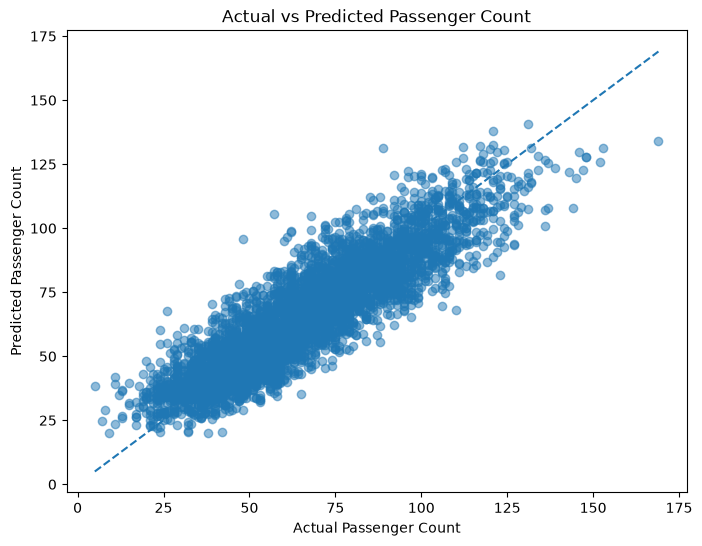

In [ ]:


plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Passenger Count")
plt.ylabel("Predicted Passenger Count")
plt.title("Actual vs Predicted Passenger Count")

plt.show()

In [ ]:
import joblib

joblib.dump(
    model,
    "sanchaar_passenger_prediction_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!
